<a href="https://colab.research.google.com/github/spyrides/CN/blob/main/quest5CN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Guilherme Miguel Spyrides Leite Ferro 176466

<>:66: SyntaxWarning: invalid escape sequence '\i'
<>:71: SyntaxWarning: invalid escape sequence '\i'
<>:66: SyntaxWarning: invalid escape sequence '\i'
<>:71: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_1536/4138210600.py:66: SyntaxWarning: invalid escape sequence '\i'
  ax2.plot(k_erro, erro_vals, marker='D', color='crimson', linewidth=2, label='$||x^{(k)} - x^{(k-1)}||_{\infty}$')
/tmp/ipykernel_1536/4138210600.py:71: SyntaxWarning: invalid escape sequence '\i'
  ax2.set_ylabel('Erro $||x^{(k)} - x^{(k-1)}||_{\infty}$ (escala log)', fontsize=11)


=== RESULTADOS DA QUESTÃO 5 ===
Número de iterações realizadas: 6
Solução aproximada obtida: x = 1.00000003, y = 1.99999998, z = -1.00000001
Erro final ||x^(6) - x^(5)||_inf: 1.26260694e-06

=== TABELA DA QUESTÃO 6 ===
 k      x^(k)      y^(k)       z^(k)  ||x^(k) - x^(k-1)||_inf
 0 0.00000000 0.00000000  0.00000000                      NaN
 1 0.60000000 2.05454545 -0.91454545               2.05454545
 2 0.98836364 2.00671074 -0.99700165               0.38836364
 3 1.00007140 2.00027907 -0.99998637               0.01170777
 4 1.00002518 2.00000353 -1.00000468               0.00027554
 5 1.00000129 1.99999969 -1.00000029               0.00002389
 6 1.00000003 1.99999998 -1.00000001               0.00000126


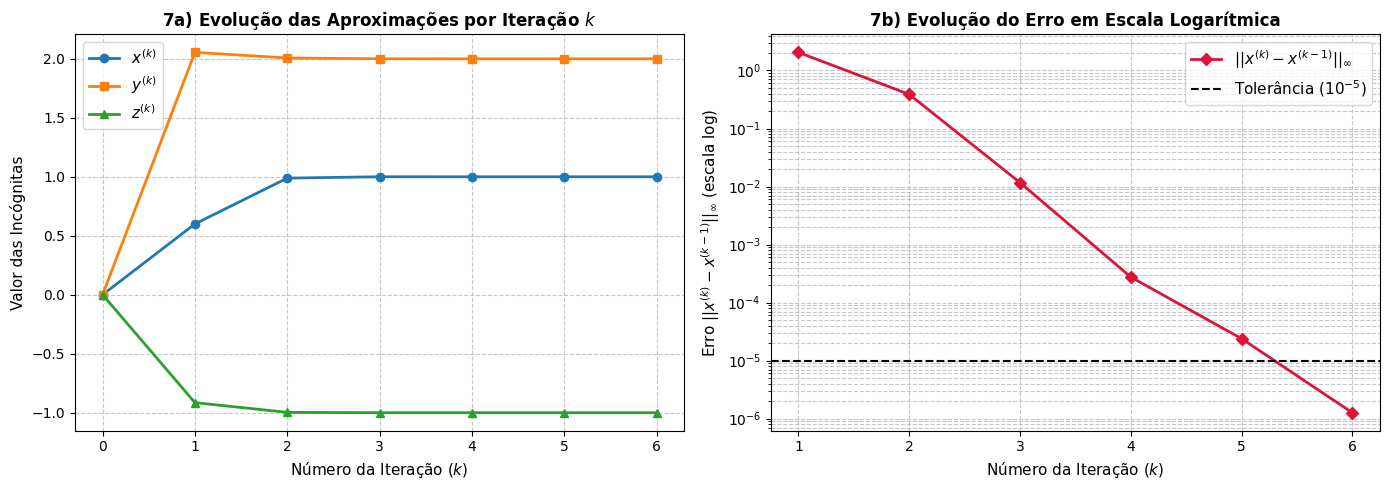

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

x, y, z = 0.0, 0.0, 0.0
tol = 1e-5
max_iter = 100

historico = [{
    'k': 0,
    'x^(k)': x,
    'y^(k)': y,
    'z^(k)': z,
    '||x^(k) - x^(k-1)||_inf': np.nan
}]

for k in range(1, max_iter + 1):
    x_ant, y_ant, z_ant = x, y, z

    x = (6.0 + y_ant - 2.0 * z_ant) / 10.0
    y = (22.0 + x + z_ant) / 11.0
    z = (-10.0 - 2.0 * x + y) / 10.0

    erro_inf = max(abs(x - x_ant), abs(y - y_ant), abs(z - z_ant))

    historico.append({
        'k': k,
        'x^(k)': x,
        'y^(k)': y,
        'z^(k)': z,
        '||x^(k) - x^(k-1)||_inf': erro_inf
    })

    if erro_inf < tol:
        break

print("=== RESULTADOS DA QUESTÃO 5 ===")
print(f"Número de iterações realizadas: {k}")
print(f"Solução aproximada obtida: x = {x:.8f}, y = {y:.8f}, z = {z:.8f}")
print(f"Erro final ||x^({k}) - x^({k-1})||_inf: {erro_inf:.8e}\n")

df_tabela = pd.DataFrame(historico)
print("=== TABELA DA QUESTÃO 6 ===")
print(df_tabela.to_string(index=False, float_format=lambda val: f"{val:.8f}"))

k_vals = df_tabela['k']
x_vals = df_tabela['x^(k)']
y_vals = df_tabela['y^(k)']
z_vals = df_tabela['z^(k)']

k_erro = df_tabela['k'][1:]
erro_vals = df_tabela['||x^(k) - x^(k-1)||_inf'][1:]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(k_vals, x_vals, marker='o', label='$x^{(k)}$', linewidth=2)
ax1.plot(k_vals, y_vals, marker='s', label='$y^{(k)}$', linewidth=2)
ax1.plot(k_vals, z_vals, marker='^', label='$z^{(k)}$', linewidth=2)
ax1.set_title('7a) Evolução das Aproximações por Iteração $k$', fontsize=12, fontweight='bold')
ax1.set_xlabel('Número da Iteração ($k$)', fontsize=11)
ax1.set_ylabel('Valor das Incógnitas', fontsize=11)
ax1.set_xticks(k_vals)
ax1.grid(True, linestyle='--', alpha=0.7)
ax1.legend(fontsize=11)

ax2.plot(k_erro, erro_vals, marker='D', color='crimson', linewidth=2, label='$||x^{(k)} - x^{(k-1)}||_{\infty}$')
ax2.axhline(tol, color='black', linestyle='--', label='Tolerância ($10^{-5}$)')
ax2.set_yscale('log')
ax2.set_title('7b) Evolução do Erro em Escala Logarítmica', fontsize=12, fontweight='bold')
ax2.set_xlabel('Número da Iteração ($k$)', fontsize=11)
ax2.set_ylabel('Erro $||x^{(k)} - x^{(k-1)}||_{\infty}$ (escala log)', fontsize=11)
ax2.set_xticks(k_erro)
ax2.grid(True, which="both", linestyle='--', alpha=0.7)
ax2.legend(fontsize=11)

plt.tight_layout()
plt.show()